#### Load and prepare data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

train = pd.read_parquet(PROJECT_ROOT / 'data/preprocessed/train.parquet')
valid = pd.read_parquet(PROJECT_ROOT / 'data/preprocessed/valid.parquet')   

In [13]:
columns = train.columns.tolist()
vehicle_columns = [x for x in columns if x.startswith("VEHICLE_")]
collision_columns = [x for x in columns if x not in vehicle_columns+["severity", "collision_index"]]

In [14]:
X_train_A = train[collision_columns]
X_train_B = train[collision_columns+vehicle_columns]
X_valid_A = valid[collision_columns]
X_valid_B = valid[collision_columns+vehicle_columns]

y_train = train["severity"]
y_valid = valid["severity"]

#### Start with a simple dummy classifier

In [15]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier()
dummy.fit(X_train_A, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.77,0.23]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](138,)","['police_force_1','police_force_10','police_force_11',..., 'urban_or_rural_area_1','urban_or_rural_area_2','urban_or_rural_area_3']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,138
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


#### The dummy classifier is trained only on features from feature set A as it only looks at the target values, so giving it features from feature set B would have the same result

In [16]:
from sklearn.metrics import average_precision_score

dummy_pred_proba = dummy.predict_proba(X_valid_A)[:,1]

dummy_avg_prec_sc = average_precision_score(y_valid, dummy_pred_proba)

print(f"dummy classifier average precision score: {dummy_avg_prec_sc}")

dummy classifier average precision score: 0.24838744835376064


#### Logistic regression

In [17]:
from sklearn.linear_model import LogisticRegression

log_reg_A = LogisticRegression(max_iter=1000)
log_reg_A.fit(X_train_A, y_train)

log_reg_B = LogisticRegression(max_iter=1000)
log_reg_B.fit(X_train_B, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [18]:
from sklearn.metrics import precision_recall_curve


def evaluate_models(models, X_valid_A=X_valid_A,
                   X_valid_B=X_valid_B, y_valid=y_valid, savefig=None, title=None):

    models_pred_proba = []
    print(f"dummy classifier average precision score: {y_valid.mean()}")
    for model in models:

        model_A_pred_proba = model[0].predict_proba(X_valid_A)[:,1]
        model_B_pred_proba = model[1].predict_proba(X_valid_B)[:,1]

        model_A_avg_prec_sc = average_precision_score(y_valid, model_A_pred_proba)
        model_B_avg_prec_sc = average_precision_score(y_valid, model_B_pred_proba)
        
        print(f"{model[2]} average precision scores:\n feature set A: {model_A_avg_prec_sc} \n feature set B: {model_B_avg_prec_sc}")

        precisions_model_A, recalls_model_A, thresholds_model_A = precision_recall_curve(y_valid, model_A_pred_proba)
        precisions_model_B, recalls_model_B, thresholds_model_B = precision_recall_curve(y_valid, model_B_pred_proba)

        plt.plot(recalls_model_A, precisions_model_A, label=model[2] + " model on feature set A")
        plt.plot(recalls_model_B, precisions_model_B, label=model[2] + " model on feature set B")

    plt.axhline(y=y_valid.mean(), label="Dummy baseline", linestyle="--", color="grey")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid()
    if title != None:
        plt.title(title)
    if savefig==True:
        plt.savefig(PROJECT_ROOT / ("outputs/figures/modelling_evaluation.png"))
    plt.show()

dummy classifier average precision score: 0.24838744835376064
logistic regression average precision scores:
 feature set A: 0.33550468447435666 
 feature set B: 0.4166313990720511


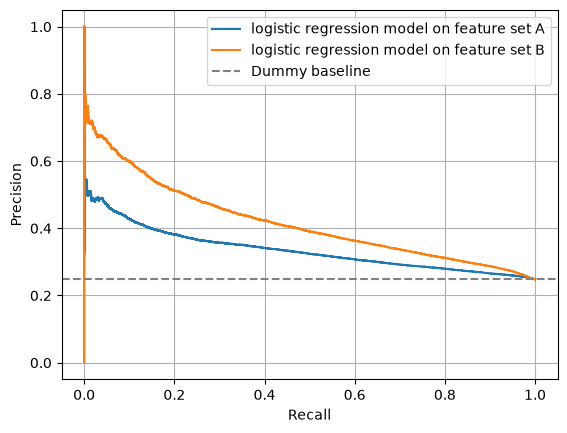

In [19]:
evaluate_models([[log_reg_A, log_reg_B, "logistic regression"]])

#### Random forest classifiers

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

In [21]:
params_A = {"n_estimators" : [30, 50, 70, 100], "max_features" : [5, 7, 10, 14, 19], 
            "min_samples_leaf" : [3, 7, 12], "max_depth" : [10, 20, 30]}

rfc_A = RandomForestClassifier(random_state=42)

cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search_rfc_A = RandomizedSearchCV(rfc_A, params_A, scoring="average_precision", 
                                       cv=cv, n_jobs=2, n_iter=15, random_state=42)

grid_search_rfc_A.fit(X_train_A, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': [5, 7, ...], 'min_samples_leaf': [3, 7, ...], 'n_estimators': [30, 50, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Randomize

In [22]:
params_B = {"n_estimators" : [30, 50, 70, 100], "max_features" : [5, 7, 10, 14, 19], 
            "min_samples_leaf" : [3, 7, 12], "max_depth" : [10, 20, 30]}

rfc_B = RandomForestClassifier(random_state=42)

cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search_rfc_B = RandomizedSearchCV(rfc_B, params_B, scoring="average_precision", 
                                       cv=cv, n_jobs=2, n_iter=30, random_state=42)

grid_search_rfc_B.fit(X_train_B, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': [5, 7, ...], 'min_samples_leaf': [3, 7, ...], 'n_estimators': [30, 50, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Randomize

In [23]:
grid_search_rfc_A.best_params_

{'n_estimators': 70,
 'min_samples_leaf': 12,
 'max_features': 7,
 'max_depth': 30}

In [24]:
grid_search_rfc_B.best_params_

{'n_estimators': 100,
 'min_samples_leaf': 3,
 'max_features': 14,
 'max_depth': 30}

#### These parameters are too close to the search boundaries

In [25]:
params_A_second = {"n_estimators" : [70], "max_features" : [7], 
            "min_samples_leaf" : [12, 15, 20], "max_depth" : [30, 40, 50]}

grid_search_rfc_A_second = GridSearchCV(rfc_A, params_A_second, scoring="average_precision", 
                                       cv=cv, n_jobs=2)

grid_search_rfc_A_second.fit(X_train_A, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [30, 40, ...], 'max_features': [7], 'min_samples_leaf': [12, 15, ...], 'n_estimators': [70]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [29]:
params_B_second = {"n_estimators" : [100, 125, 150], "max_features" : [14], 
            "min_samples_leaf" : [3], "max_depth" : [30, 40, 50]}

grid_search_rfc_B_second = GridSearchCV(rfc_B, params_B_second, scoring="average_precision", 
                                       cv=cv, n_jobs=2)

grid_search_rfc_B_second.fit(X_train_B, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [30, 40, ...], 'max_features': [14], 'min_samples_leaf': [3], 'n_estimators': [100, 125, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [30]:
grid_search_rfc_A_second.best_params_

{'max_depth': 50,
 'max_features': 7,
 'min_samples_leaf': 12,
 'n_estimators': 70}

In [31]:
grid_search_rfc_B_second.best_params_

{'max_depth': 30,
 'max_features': 14,
 'min_samples_leaf': 3,
 'n_estimators': 150}

In [32]:
best_rfc_A = grid_search_rfc_A_second.best_estimator_
best_rfc_B = grid_search_rfc_B_second.best_estimator_

In [33]:
import joblib

joblib.dump(best_rfc_A, PROJECT_ROOT / "models/modelling_rfc_A.joblib")
joblib.dump(best_rfc_B, PROJECT_ROOT / "models/modelling_rfc_B.joblib")

['c:\\sskola\\python\\collisions\\models\\modelling_rfc_B.joblib']

In [34]:
import joblib

best_rfc_A = joblib.load(PROJECT_ROOT / "models/modelling_rfc_A.joblib")
best_rfc_B = joblib.load(PROJECT_ROOT / "models/modelling_rfc_B.joblib")

dummy classifier average precision score: 0.24838744835376064
random forest classifier average precision scores:
 feature set A: 0.34827016669323174 
 feature set B: 0.45131485376046754


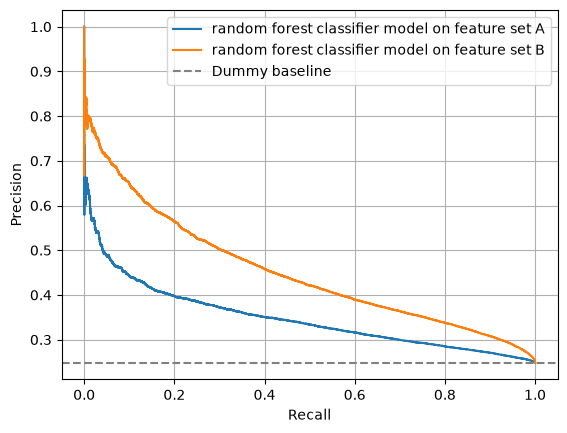

In [35]:
evaluate_models([[best_rfc_A, best_rfc_B, "random forest classifier"]])

dummy classifier average precision score: 0.24838744835376064
logistic regression average precision scores:
 feature set A: 0.33550468447435666 
 feature set B: 0.4166313990720511
random forest classifier average precision scores:
 feature set A: 0.34827016669323174 
 feature set B: 0.45131485376046754


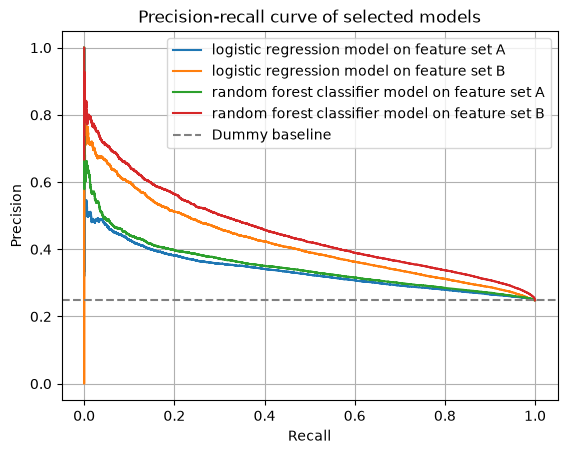

In [36]:
evaluate_models([[log_reg_A, log_reg_B, "logistic regression"], 
                 [best_rfc_A, best_rfc_B, "random forest classifier"]], 
                 savefig=True, title="Precision-recall curve of selected models")

#### Although the logistic regression model performed marginally better on the feature set A, we will still use the random forest classifier on feature set A as our final model so we can better compare it with the random forest classifier on feature set B.

#### RFC models on datasets A and B comparison

In [37]:
from scipy.stats import bootstrap

def statistic(y_valid, A_pred_proba, B_pred_proba):
    return average_precision_score(y_valid, B_pred_proba) - average_precision_score(y_valid, A_pred_proba)

boot = bootstrap(data=(y_valid, best_rfc_A.predict_proba(X_valid_A)[:,1], best_rfc_B.predict_proba(X_valid_B)[:,1]), 
              statistic = statistic, confidence_level=0.95, paired=True, 
              n_resamples=1000, method="percentile", random_state=42)

print(f"95% confidence interval for the difference in average precision scores between rfc models on datasets B and A:" +
       f"\n{round(float(boot.confidence_interval[0]),4)} - {round(float(boot.confidence_interval[1]), 4)}")

95% confidence interval for the difference in average precision scores between rfc models on datasets B and A:
0.0979 - 0.1083


Text(0.5, 1.0, 'Histogram of the diference between AP scores on feature \nsets B and A paired-bootstrap resampled 1000 times')

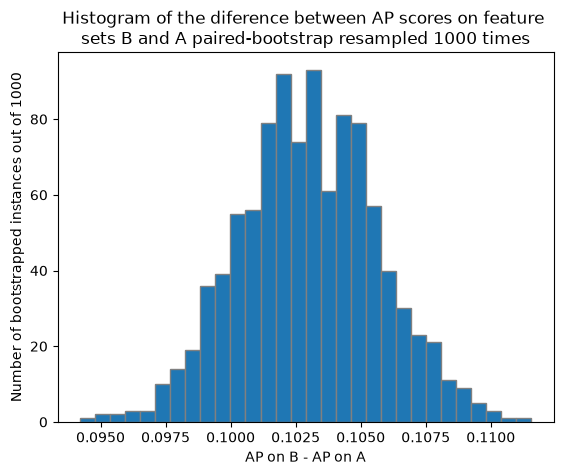

In [38]:
plt.hist(boot.bootstrap_distribution, bins=30, edgecolor="grey")
plt.xlabel("AP on B - AP on A")
plt.ylabel("Number of bootstrapped instances out of 1000")
plt.title("Histogram of the diference between AP scores on feature \nsets B and A paired-bootstrap resampled 1000 times")